# Predicting Student Performance and Adaptive Learning
### Dataset 1: ASSISTments 2009–2010 Skill Builder Data
**Models compared:** Bayesian Knowledge Tracing (BKT) · Logistic Regression · Decision Tree · Random Forest

---
## Project at a glance
**Goal:** Use students' past answers to (1) predict whether their *next* answer will be correct, and (2) estimate how well they have learned each skill, so a learning system can decide what to practise next.

**The 5 steps of this notebook**
1. **Load and clean** the data
2. **Explore** it with simple statistics and charts
3. **Split** students into a training group (80%) and a testing group (20%)
4. **Train and test** four models
5. **Compare** the models and use BKT to give practice recommendations

**Main result (short):** BKT gave the best accuracy (≈70%) and the best-calibrated probabilities. Random Forest ranked students' answers best (highest ROC-AUC, 0.72). All four models are in a similar range, which shows that predicting student answers is genuinely difficult.

## 1. Importing Libraries
**In simple words:** We load the Python tools we need: *pandas* for tables, *matplotlib/seaborn* for charts, *scikit-learn* for the machine-learning models, and *scipy* to fit BKT.

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, log_loss,
    roc_curve
)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 100)

## 2. Loading the Dataset
**In simple words:** We read the ASSISTments file. Each row is one answer given by one student to one maths problem. The code looks for the file automatically and asks for an upload if it is missing (Google Colab).

In [4]:
# Look for the CSV in common places; if it is not found, ask for an upload (Google Colab)
candidates = [
    "skill_builder_data_corrected_collapsed.csv",
    "skill_builder_data_corrected_collapsed(1).csv",
    "/content/skill_builder_data_corrected_collapsed.csv",
    "/content/skill_builder_data_corrected_collapsed(1).csv",
]
DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)

if DATA_PATH is None:
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = next(iter(uploaded))

df = pd.read_csv(DATA_PATH, encoding="cp1252", low_memory=False)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Saving skill_builder_data_corrected_collapsed.csv to skill_builder_data_corrected_collapsed.csv
Dataset loaded successfully.
Shape: (346860, 31)


## 3. Initial Dataset Inspection
**In simple words:** A first look at the raw data: a few rows, the column names, and the type of each column.

**What we see:** The raw file has **346,860 rows and 31 columns**.

In [5]:
display(df.head())
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values
}))

,Unnamed: 0,order_id,assignment_id,user_id,assistment_id,problem_id,original,correct,attempt_count,ms_first_response,tutor_mode,answer_type,sequence_id,student_class_id,position,type,base_sequence_id,skill_id,skill_name,teacher_id,school_id,hint_count,hint_total,overlap_time,template_id,answer_id,answer_text,first_action,bottom_hint,opportunity,opportunity_original
0,1,33022537,277618,64525,33139,51424,1,1,1,32454,tutor,algebra,5948,13241,126,MasterySection,5948,1_13,Box and Whisker,22763,73,0,3,32454,30799,NaN,26,0,NaN,1,1.0
1,2,33022709,277618,64525,33150,51435,1,1,1,4922,tutor,algebra,5948,13241,126,MasterySection,5948,1_13,Box and Whisker,22763,73,0,3,4922,30799,NaN,55,0,NaN,2,2.0
2,3,35450204,220674,70363,33159,51444,1,0,2,25390,tutor,algebra,5948,11816,22,MasterySection,5948,1_13,Box and Whisker,22763,73,0,3,42000,30799,NaN,88,0,NaN,1,1.0
3,4,35450295,220674,70363,33110,51395,1,1,1,4859,tutor,algebra,5948,11816,22,MasterySection,5948,1_13,Box and Whisker,22763,73,0,3,4859,30059,NaN,41,0,NaN,2,2.0
4,5,35450311,220674,70363,33196,51481,1,0,14,19813,tutor,algebra,5948,11816,22,MasterySection,5948,1_15,Box and Whisker,22763,73,3,4,124564,30060,NaN,65,0,0.0,3,3.0


Rows: 346860
Columns: 31


,Column,Data Type,Missing Values
0,Unnamed: 0,int64,0
1,order_id,int64,0
2,assignment_id,int64,0
3,user_id,int64,0
4,assistment_id,int64,0
5,problem_id,int64,0
6,original,int64,0
7,correct,int64,0
8,attempt_count,int64,0
9,ms_first_response,int64,0


## 4. Missing Value Analysis
**In simple words:** We check which columns have empty cells.

**What we see:** Several columns have many gaps (e.g. `answer_id` 88%, `bottom_hint` 83%). The most important one for us is **`skill_id`, which is missing in about 18% of rows**. BKT needs to know the skill, so those rows cannot be used.

,Missing Values,Missing Percentage
answer_id,306818,88.455861
bottom_hint,287003,82.743182
answer_text,77630,22.380788
skill_name,72270,20.835496
opportunity_original,71402,20.585251
skill_id,63755,18.380615


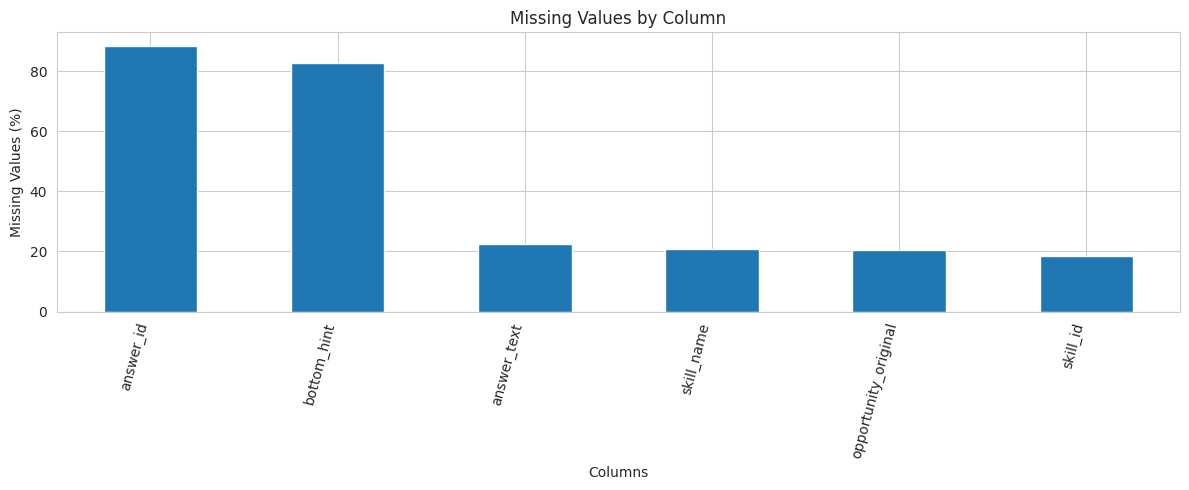

In [6]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary[missing_summary["Missing Values"] > 0])

plt.figure(figsize=(12, 5))
missing_summary[missing_summary["Missing Values"] > 0]["Missing Percentage"].plot(kind="bar")
plt.title("Missing Values by Column")
plt.ylabel("Missing Values (%)")
plt.xlabel("Columns")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 5. Duplicate Record Analysis
**In simple words:** We check that no row is repeated. **Result: 0 duplicate rows.**

In [7]:
print("Fully duplicated rows:", df.duplicated().sum())

Fully duplicated rows: 0


## 6. Target Variable Distribution
**In simple words:** The thing we want to predict is `correct` (1 = right answer, 0 = wrong answer). Here we see how often each happens.

**What we see:** About **64.5% of answers are correct** (223,818 correct vs 123,042 incorrect). So a "model" that always guessed *correct* would already be right about 65% of the time. This is the **baseline** that our models must beat.

,Count
correct,
1,223818
0,123042


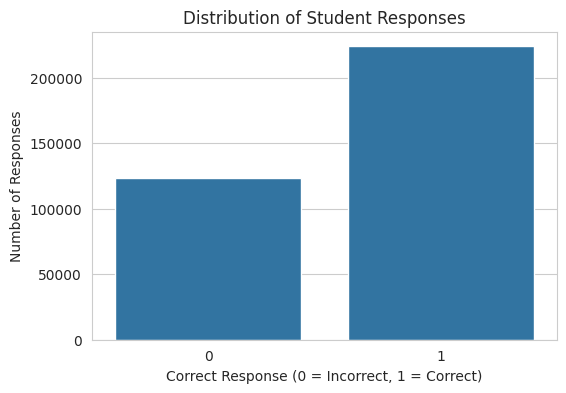

Correct response percentage: 64.53


In [8]:
display(df["correct"].value_counts(dropna=False).rename("Count").to_frame())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="correct")
plt.title("Distribution of Student Responses")
plt.xlabel("Correct Response (0 = Incorrect, 1 = Correct)")
plt.ylabel("Number of Responses")
plt.show()

print("Correct response percentage:", round(df["correct"].mean() * 100, 2))

## 7. Data Cleaning and Selection
**In simple words:** We keep only the columns we need and remove rows with missing student, skill, order or answer information. Then we sort each student's answers in the order they were attempted.

**Result:** Rows drop from 346,860 to **283,105** (mainly rows without a skill ID), and we keep **9 useful columns**.

In [9]:
data = df.drop(columns=["Unnamed: 0"], errors="ignore").copy()

required_columns = [
    "order_id", "user_id", "problem_id", "correct",
    "attempt_count", "skill_id", "skill_name",
    "hint_count", "opportunity"
]

data = data[required_columns].copy()

data = data.dropna(subset=[
    "order_id", "user_id", "correct", "skill_id"
])

data["correct"] = pd.to_numeric(data["correct"], errors="coerce")
data["order_id"] = pd.to_numeric(data["order_id"], errors="coerce")
data["user_id"] = pd.to_numeric(data["user_id"], errors="coerce")

data = data.dropna(subset=["correct", "order_id", "user_id"])
data = data[data["correct"].isin([0, 1])].copy()

for column in ["attempt_count", "hint_count", "opportunity"]:
    data[column] = pd.to_numeric(data[column], errors="coerce")

data["skill_id"] = data["skill_id"].astype(str)
data["skill_name"] = data["skill_name"].fillna("Unknown Skill").astype(str)

data = data.sort_values(["user_id", "skill_id", "order_id"]).reset_index(drop=True)

print("Cleaned data shape:", data.shape)
display(data.head())

Cleaned data shape: (283105, 9)


,order_id,user_id,problem_id,correct,attempt_count,skill_id,skill_name,hint_count,opportunity
0,21617893,14,91522,0,1,13,Median,2,1
1,21617931,14,91144,0,1,13,Median,3,2
2,21617953,14,91124,0,1,13,Median,2,3
3,21617962,14,91127,0,1,13,Median,3,4
4,21617915,14,92390,1,1,15,Range,0,1


## 8. Descriptive Statistics
**In simple words:** Basic summary numbers (average, minimum, maximum, etc.) for the cleaned data.

In [10]:
display(data.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,283105.0,NaN,NaN,NaN,30515823.969358,5262535.861391,20224085.0,26446450.0,30742839.0,34899660.0,38310202.0
user_id,283105.0,NaN,NaN,NaN,83456.86913,7365.037141,14.0,78970.0,80231.0,88127.0,96299.0
problem_id,283105.0,NaN,NaN,NaN,81895.478791,23170.498663,83.0,60094.0,85818.0,91501.0,196456.0
correct,283105.0,NaN,NaN,NaN,0.658137,0.474335,0.0,0.0,1.0,1.0,1.0
attempt_count,283105.0,NaN,NaN,NaN,1.599714,13.137263,0.0,1.0,1.0,1.0,3824.0
skill_id,283105,149,311,24253,NaN,NaN,NaN,NaN,NaN,NaN,NaN
skill_name,283105,102,Equation Solving Two or Fewer Steps,24253,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hint_count,283105.0,NaN,NaN,NaN,0.450812,1.175798,0.0,0.0,0.0,0.0,7.0
opportunity,283105.0,NaN,NaN,NaN,15.552177,67.013741,1.0,3.0,7.0,14.0,3371.0


## 9. Student and Skill Statistics
**In simple words:** How many students, skills, and "learning sequences" do we have? A *sequence* is one student's answers to one skill, in time order.

**Result:** **4,163 students**, 149 skill IDs (102 skill names) and **42,995 student-skill sequences**. A typical sequence is short (average 6.6 answers, median 4), so for many sequences there is little information.

In [11]:
print("Unique students:", data["user_id"].nunique())
print("Unique skill IDs:", data["skill_id"].nunique())
print("Unique skill names:", data["skill_name"].nunique())

sequence_counts = data.groupby(["user_id", "skill_id"]).size()

print("Student-skill sequences:", len(sequence_counts))
print("Mean sequence length:", round(sequence_counts.mean(), 2))
print("Median sequence length:", round(sequence_counts.median(), 2))

Unique students: 4163
Unique skill IDs: 149
Unique skill names: 102
Student-skill sequences: 42995
Mean sequence length: 6.58
Median sequence length: 4.0


## 10. Exploratory Data Analysis
**In simple words:** Charts that show (left) correct vs incorrect answers, (right) the most practised skills, and (below) how many answers each student gave.

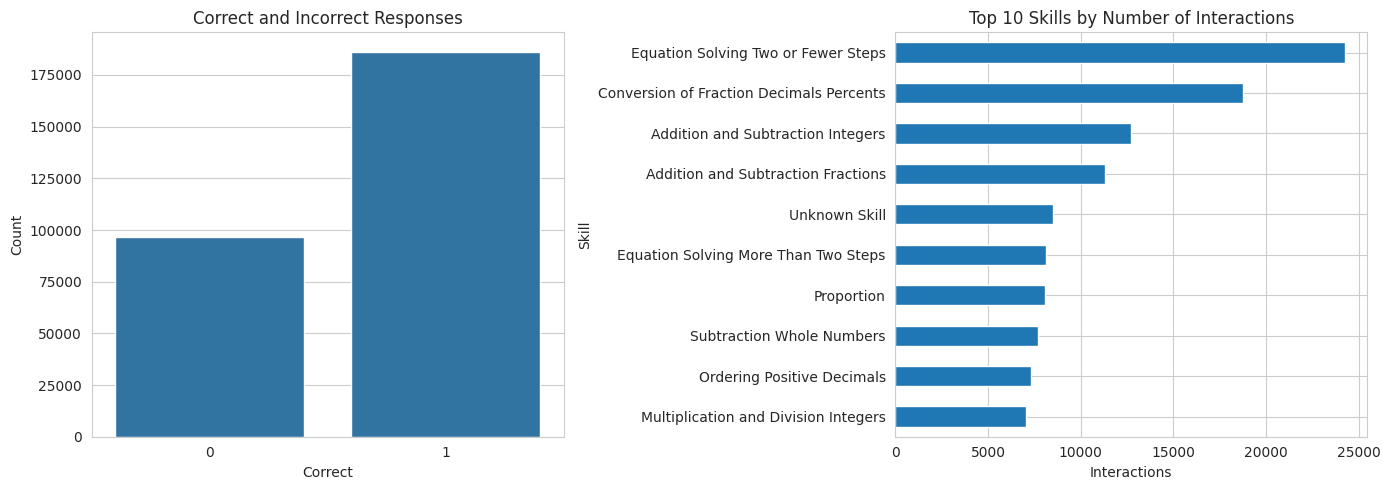

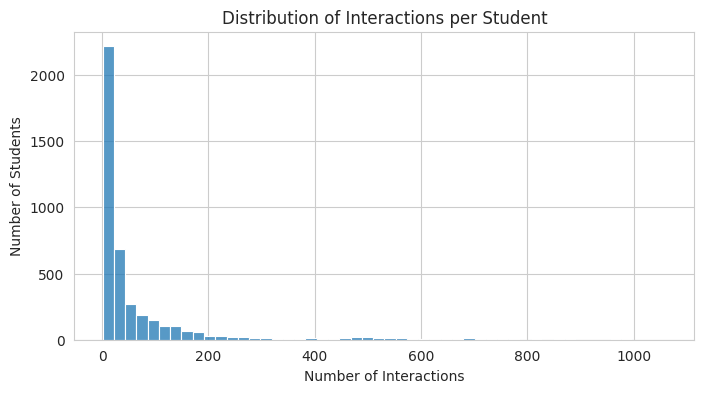

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=data, x="correct", ax=axes[0])
axes[0].set_title("Correct and Incorrect Responses")
axes[0].set_xlabel("Correct")
axes[0].set_ylabel("Count")

top_skills = data["skill_name"].value_counts().head(10)
top_skills.sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 10 Skills by Number of Interactions")
axes[1].set_xlabel("Interactions")
axes[1].set_ylabel("Skill")

plt.tight_layout()
plt.show()

student_interactions = data.groupby("user_id").size()

plt.figure(figsize=(8, 4))
sns.histplot(student_interactions, bins=50)
plt.title("Distribution of Interactions per Student")
plt.xlabel("Number of Interactions")
plt.ylabel("Number of Students")
plt.show()

## 11. Preparing Student-Level Train-Test Data
**In simple words:** We keep 80% of students for **training** (the model learns from them) and 20% for **testing** (we check how well it predicts for students it has never seen). We split by *student*, not by row, so the same student is never in both groups. This keeps the test fair.

**Result:** 3,330 training students (225,892 answers) and 833 test students (57,213 answers). **Overlap = 0.**

In [13]:
from sklearn.model_selection import train_test_split

students = data["user_id"].drop_duplicates()

train_students, test_students = train_test_split(
    students,
    test_size=0.20,
    random_state=42
)

train_data = data[data["user_id"].isin(train_students)].copy()
test_data = data[data["user_id"].isin(test_students)].copy()

print("Training students:", train_data["user_id"].nunique())
print("Testing students:", test_data["user_id"].nunique())
print("Training interactions:", len(train_data))
print("Testing interactions:", len(test_data))
print("Student overlap:", len(set(train_students) & set(test_students)))

Training students: 3330
Testing students: 833
Training interactions: 225892
Testing interactions: 57213
Student overlap: 0


## 12. Creating Sequential Features for Classification Models
**In simple words:** The three classification models need inputs ("features"). We build them only from what happened **before** the current question, so the model never sees the answer it is trying to predict:
- `prior_interactions`: how many times the student practised this skill before
- `prior_correct_rate`: share of earlier answers that were correct
- `prior_avg_attempts` / `prior_avg_hints`: average attempts and hints used earlier
- `opportunity` and `skill_id`: which attempt this is and which skill it is

In [14]:
def create_sequential_features(frame):
    frame = frame.sort_values(
        ["user_id", "skill_id", "order_id"]
    ).copy()

    grouped = frame.groupby(["user_id", "skill_id"], sort=False)

    frame["prior_interactions"] = grouped.cumcount()
    frame["prior_correct_count"] = grouped["correct"].transform(
        lambda values: values.shift().fillna(0).cumsum()
    )
    frame["prior_correct_rate"] = (
        frame["prior_correct_count"] /
        frame["prior_interactions"].replace(0, np.nan)
    )

    frame["prior_avg_attempts"] = grouped["attempt_count"].transform(
        lambda values: values.shift().expanding().mean()
    )
    frame["prior_avg_hints"] = grouped["hint_count"].transform(
        lambda values: values.shift().expanding().mean()
    )

    frame["prior_correct_rate"] = frame["prior_correct_rate"].fillna(0)
    frame["prior_avg_attempts"] = frame["prior_avg_attempts"].fillna(0)
    frame["prior_avg_hints"] = frame["prior_avg_hints"].fillna(0)

    frame["skill_id"] = frame["skill_id"].fillna("Unknown").astype(str)
    frame["opportunity"] = frame["opportunity"].fillna(0)

    return frame

train_features = create_sequential_features(train_data)
test_features = create_sequential_features(test_data)

feature_columns = [
    "skill_id",
    "opportunity",
    "prior_interactions",
    "prior_correct_rate",
    "prior_avg_attempts",
    "prior_avg_hints"
]

X_train = train_features[feature_columns]
y_train = train_features["correct"].astype(int)

X_test = test_features[feature_columns]
y_test = test_features["correct"].astype(int)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training feature shape: (225892, 6)
Testing feature shape: (57213, 6)


## 13. Defining the Classification Models
**In simple words:** We train three standard machine-learning models to predict *correct / incorrect*:
- **Logistic Regression:** a simple model that combines the features with weights.
- **Decision Tree:** a flow-chart of yes/no questions.
- **Random Forest:** many decision trees voting together.

`class_weight="balanced"` stops the models from always predicting the common answer ("correct").

In [15]:
numeric_features = [
    "opportunity",
    "prior_interactions",
    "prior_correct_rate",
    "prior_avg_attempts",
    "prior_avg_hints"
]

categorical_features = ["skill_id"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=16,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    )
}

fitted_models = {}
classification_predictions = {}
classification_probabilities = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    fitted_models[name] = pipeline
    classification_predictions[name] = pipeline.predict(X_test)
    classification_probabilities[name] = pipeline.predict_proba(X_test)[:, 1]

print("All classification models trained.")

All classification models trained.


## 14. Evaluating Classification Models
**In simple words:** We test each model on the unseen test students. See the **metric guide** at the end of this notebook for what each score means.

**Result:** Logistic Regression has the best accuracy (66.2%), Random Forest the best ROC-AUC (0.722), and Decision Tree is the weakest (64.1%).

In [16]:
classification_results = []

for name in fitted_models:
    predictions = classification_predictions[name]
    probabilities = classification_probabilities[name]

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Brier Score": brier_score_loss(y_test, probabilities),
        "Log Loss": log_loss(y_test, probabilities)
    })

classification_results_df = pd.DataFrame(classification_results)
display(classification_results_df.sort_values("Accuracy", ascending=False))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Brier Score,Log Loss
0,Logistic Regression,0.662175,0.783163,0.672514,0.723633,0.713596,0.213244,0.615779
2,Random Forest,0.659990,0.783254,0.667783,0.720924,0.722377,0.211931,0.613213
1,Decision Tree,0.641113,0.781886,0.630043,0.697800,0.703698,0.213927,0.644081


## 15. Classification Model Visualizations
**In simple words:** A bar chart of accuracy, and ROC curves. The higher a curve is above the dotted diagonal line, the better the model separates correct from incorrect answers.

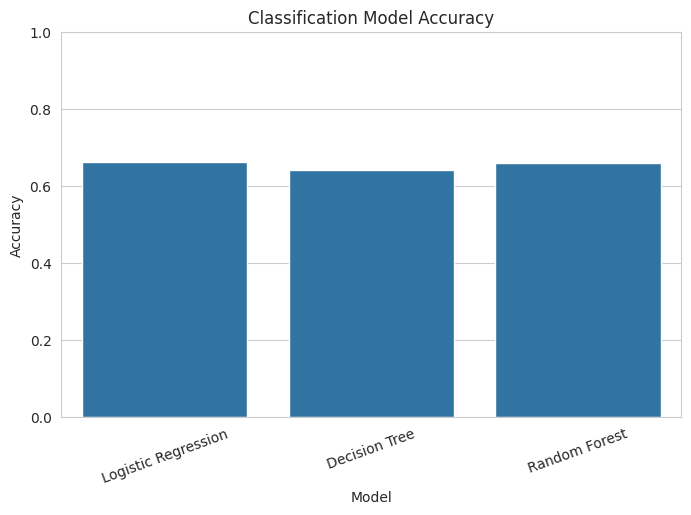

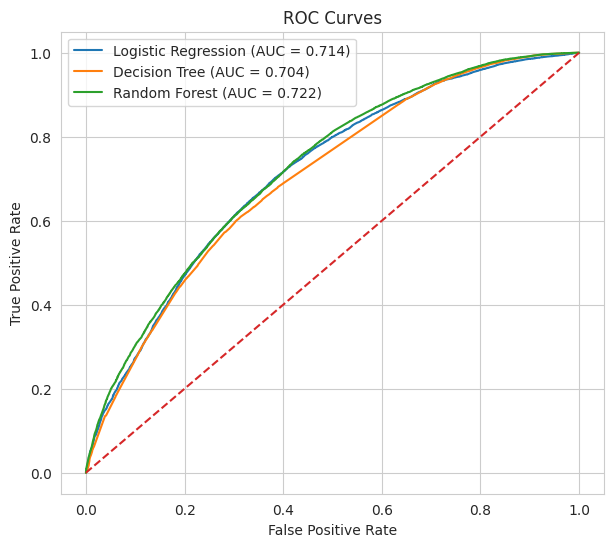

In [17]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=classification_results_df,
    x="Model",
    y="Accuracy"
)
plt.title("Classification Model Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

plt.figure(figsize=(7, 6))

for name, probabilities in classification_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

### Which clues does the Random Forest use most?
**In simple words:** This chart shows which inputs (features) the Random Forest relied on most when predicting. Longer bar = more important. All the `skill_id` categories are combined into one bar.

In [ ]:
rf_pipeline = fitted_models["Random Forest"]
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances = rf_pipeline.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importances})
importance_df["Feature"] = (
    importance_df["Feature"]
    .str.replace("numeric__", "", regex=False)
    .apply(lambda name: "skill_id" if name.startswith("categorical__") else name)
)
importance_df = (
    importance_df.groupby("Feature", as_index=False)["Importance"].sum()
    .sort_values("Importance")
)

plt.figure(figsize=(8, 4))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.title("Random Forest: Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

**How to read it:** The student's earlier performance on the skill (such as `prior_correct_rate`) is expected to matter most. This makes sense: a student who answered well before is likely to answer well again.

## 16. Bayesian Knowledge Tracing (BKT)
**In simple words:** BKT follows one student on one skill and keeps a running estimate of **"how likely is it that the student has learned this skill?"** After each answer the estimate goes up or down. It uses four numbers:

| Parameter | Meaning |
|---|---|
| **P(L0)** | chance the student already knew the skill at the start |
| **P(T)** | chance of learning the skill after each practice |
| **P(G)** | chance of **guessing** right without knowing the skill |
| **P(S)** | chance of **slipping** (a wrong answer even though the skill is known) |

In [18]:
def update_mastery(mastery, response, p_guess, p_slip):
    if response == 1:
        numerator = mastery * (1 - p_slip)
        denominator = numerator + (1 - mastery) * p_guess
    else:
        numerator = mastery * p_slip
        denominator = numerator + (1 - mastery) * (1 - p_guess)

    if denominator == 0:
        return mastery

    return numerator / denominator


def learning_transition(mastery, p_transition):
    return mastery + (1 - mastery) * p_transition


def predict_correct(mastery, p_guess, p_slip):
    return mastery * (1 - p_slip) + (1 - mastery) * p_guess


def bkt_sequence_log_likelihood(responses, params):
    p_l0, p_transition, p_guess, p_slip = params
    mastery = p_l0
    total_log_likelihood = 0.0
    epsilon = 1e-10

    for response in responses:
        probability_correct = predict_correct(
            mastery, p_guess, p_slip
        )
        probability_correct = np.clip(
            probability_correct, epsilon, 1 - epsilon
        )

        if response == 1:
            total_log_likelihood += np.log(probability_correct)
        else:
            total_log_likelihood += np.log(1 - probability_correct)

        mastery = update_mastery(
            mastery, response, p_guess, p_slip
        )
        mastery = learning_transition(mastery, p_transition)

    return total_log_likelihood


def bkt_negative_log_likelihood(params, sequences):
    total = 0.0

    for responses in sequences:
        total += bkt_sequence_log_likelihood(responses, params)

    return -total

## 17. Preparing BKT Training Sequences
**In simple words:** For BKT we group each student's answers by skill, in time order. We have **34,114 training sequences**.

In [19]:
train_sequences_df = (
    train_data.sort_values(["user_id", "skill_id", "order_id"])
    .groupby(["user_id", "skill_id"])["correct"]
    .apply(list)
    .reset_index(name="responses")
)

train_sequences = train_sequences_df["responses"].tolist()

print("Training student-skill sequences:", len(train_sequences))

Training student-skill sequences: 34114


## 18. Fitting BKT Parameters Using Maximum Likelihood Estimation
**In simple words:** We let the computer search for the four BKT numbers that best explain the training students' answers. For speed it uses a random sample of 10,000 sequences.

**Result:**
| Parameter | Value | Reading |
|---|---|---|
| P(L0) | 0.736 | most students start with some knowledge |
| P(T) | 0.059 | about 6% learning gain per practice |
| P(G) | 0.275 | answers are guessed right fairly often |
| P(S) | 0.206 | slips are also fairly common |

The optimizer **converged successfully**.

In [20]:
rng = np.random.default_rng(42)
fit_count = min(10000, len(train_sequences))
fit_indices = rng.choice(
    len(train_sequences),
    size=fit_count,
    replace=False
)
fit_sequences = [train_sequences[i] for i in fit_indices]

initial_params = [0.5, 0.1, 0.2, 0.1]
parameter_bounds = [
    (0.01, 0.99),
    (0.01, 0.99),
    (0.01, 0.49),
    (0.01, 0.49)
]

optimization_result = minimize(
    bkt_negative_log_likelihood,
    initial_params,
    args=(fit_sequences,),
    method="L-BFGS-B",
    bounds=parameter_bounds,
    options={"maxiter": 100}
)

bkt_parameters = optimization_result.x

bkt_parameter_names = [
    "P(L0)", "P(T)", "P(G)", "P(S)"
]

display(pd.DataFrame({
    "Parameter": bkt_parameter_names,
    "Estimated Value": bkt_parameters
}))

print("Optimization successful:", optimization_result.success)
print("Optimizer message:", optimization_result.message)

,Parameter,Estimated Value
0,P(L0),0.736449
1,P(T),0.058927
2,P(G),0.274609
3,P(S),0.205777


Optimization successful: True
Optimizer message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH


## 19. BKT Prediction on Test Students
**In simple words:** For each test answer, BKT first predicts the chance of a correct answer, then sees the real answer and updates its mastery estimate. Again, the model never sees an answer before predicting it.

In [21]:
def evaluate_bkt_sequences(sequence_frame, params):
    p_l0, p_transition, p_guess, p_slip = params
    records = []

    for (user_id, skill_id), group in sequence_frame.groupby(
        ["user_id", "skill_id"], sort=False
    ):
        group = group.sort_values("order_id")
        mastery = p_l0

        for row in group.itertuples(index=False):
            response = int(row.correct)
            predicted_probability = predict_correct(
                mastery, p_guess, p_slip
            )

            records.append({
                "user_id": user_id,
                "skill_id": skill_id,
                "order_id": row.order_id,
                "actual": response,
                "predicted_probability": predicted_probability,
                "predicted_class": int(predicted_probability >= 0.5),
                "mastery_before_response": mastery
            })

            mastery = update_mastery(
                mastery, response, p_guess, p_slip
            )
            mastery = learning_transition(
                mastery, p_transition
            )

    return pd.DataFrame(records)


bkt_test_results = evaluate_bkt_sequences(
    test_data, bkt_parameters
)

display(bkt_test_results.head())

,user_id,skill_id,order_id,actual,predicted_probability,predicted_class,mastery_before_response
0,58161,312,34986426,0,0.657278,1,0.736449
1,58161,312,34986765,0,0.521451,1,0.475049
2,58161,312,34986790,0,0.405116,0,0.251162
3,58161,312,34986816,0,0.347712,0,0.140687
4,58161,312,34986851,1,0.326931,0,0.100694


## 20. Evaluating BKT
**In simple words:** The same scores as the other models, so the comparison is fair.

**Result:** Accuracy **70.2%**, recall 92%, ROC-AUC 0.680. BKT says "correct" most of the time, which gives high recall but lower precision.

In [22]:
bkt_accuracy = accuracy_score(
    bkt_test_results["actual"],
    bkt_test_results["predicted_class"]
)

bkt_probabilities = np.clip(
    bkt_test_results["predicted_probability"],
    1e-10,
    1 - 1e-10
)

bkt_metrics = {
    "Model": "Bayesian Knowledge Tracing",
    "Accuracy": bkt_accuracy,
    "Precision": precision_score(
        bkt_test_results["actual"],
        bkt_test_results["predicted_class"],
        zero_division=0
    ),
    "Recall": recall_score(
        bkt_test_results["actual"],
        bkt_test_results["predicted_class"],
        zero_division=0
    ),
    "F1 Score": f1_score(
        bkt_test_results["actual"],
        bkt_test_results["predicted_class"],
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        bkt_test_results["actual"],
        bkt_test_results["predicted_probability"]
    ),
    "Brier Score": brier_score_loss(
        bkt_test_results["actual"],
        bkt_probabilities
    ),
    "Log Loss": log_loss(
        bkt_test_results["actual"],
        bkt_probabilities
    )
}

display(pd.DataFrame([bkt_metrics]))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Brier Score,Log Loss
0,Bayesian Knowledge Tracing,0.701799,0.711318,0.919896,0.802272,0.679553,0.201661,0.591409


### Example: how BKT tracks one student
**In simple words:** This picture follows one test student on one skill. The line is BKT's estimate of mastery **before** each answer. Green dots are correct answers and red crosses are wrong answers. Mastery rises after correct answers and falls after wrong ones.

In [ ]:
sequence_lengths = bkt_test_results.groupby(["user_id", "skill_id"]).size()
example_user, example_skill = sequence_lengths[sequence_lengths >= 8].index[0]

example = bkt_test_results[
    (bkt_test_results["user_id"] == example_user) &
    (bkt_test_results["skill_id"] == example_skill)
].sort_values("order_id").reset_index(drop=True)
attempts = np.arange(1, len(example) + 1)

plt.figure(figsize=(8, 4))
plt.plot(attempts, example["mastery_before_response"], marker="o", label="Estimated mastery")
plt.scatter(attempts[example["actual"] == 1], [1.03] * int((example["actual"] == 1).sum()),
            color="green", marker="o", label="Correct answer")
plt.scatter(attempts[example["actual"] == 0], [1.03] * int((example["actual"] == 0).sum()),
            color="red", marker="x", label="Wrong answer")
plt.ylim(0, 1.1)
plt.xlabel("Attempt number")
plt.ylabel("Mastery before the answer")
plt.title(f"BKT mastery estimate (student {example_user}, skill {example_skill})")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 21. Comparing All Four Models
**In simple words:** All four models side by side on the same test students.

In [23]:
all_model_results = pd.concat(
    [
        pd.DataFrame([bkt_metrics]),
        classification_results_df
    ],
    ignore_index=True
)

display(
    all_model_results.sort_values(
        "Accuracy", ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Brier Score,Log Loss
0,Bayesian Knowledge Tracing,0.701799,0.711318,0.919896,0.802272,0.679553,0.201661,0.591409
1,Logistic Regression,0.662175,0.783163,0.672514,0.723633,0.713596,0.213244,0.615779
2,Random Forest,0.659990,0.783254,0.667783,0.720924,0.722377,0.211931,0.613213
3,Decision Tree,0.641113,0.781886,0.630043,0.697800,0.703698,0.213927,0.644081


### Baseline check
**In simple words:** What if we simply guessed "correct" for every answer? That needs no model. A useful model should do better than this.

In [ ]:
baseline_accuracy = y_test.mean()
print(f"Always predicting 'correct' gives accuracy: {baseline_accuracy:.3f}")
print(f"BKT accuracy:                               {bkt_metrics['Accuracy']:.3f}")
for name in classification_predictions:
    print(f"{name + ' accuracy:':<44}{accuracy_score(y_test, classification_predictions[name]):.3f}")

**How to read it:** BKT beats the always-"correct" guess. The three classifiers have lower accuracy than that guess because they were built to catch wrong answers too (balanced class weights). So for them, ROC-AUC and the confusion matrices below are the better way to judge them.

### Confusion matrices
**In simple words:** Each box counts answers. Rows = what really happened, columns = what the model predicted. The diagonal boxes (top-left and bottom-right) are correct predictions.

In [ ]:
from sklearn.metrics import confusion_matrix

panels = {name: (y_test, classification_predictions[name]) for name in classification_predictions}
panels["Bayesian Knowledge Tracing"] = (
    bkt_test_results["actual"], bkt_test_results["predicted_class"]
)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, (actual, predicted)) in zip(axes.ravel(), panels.items()):
    matrix = confusion_matrix(actual, predicted)
    sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted Incorrect", "Predicted Correct"],
                yticklabels=["Actually Incorrect", "Actually Correct"])
    ax.set_title(name)
plt.tight_layout()
plt.show()

**How to read it:** BKT predicts "correct" for most answers, so it finds almost all correct answers but also mislabels many wrong answers as correct. The classifiers are more balanced between the two kinds of answer.

### Visual comparison

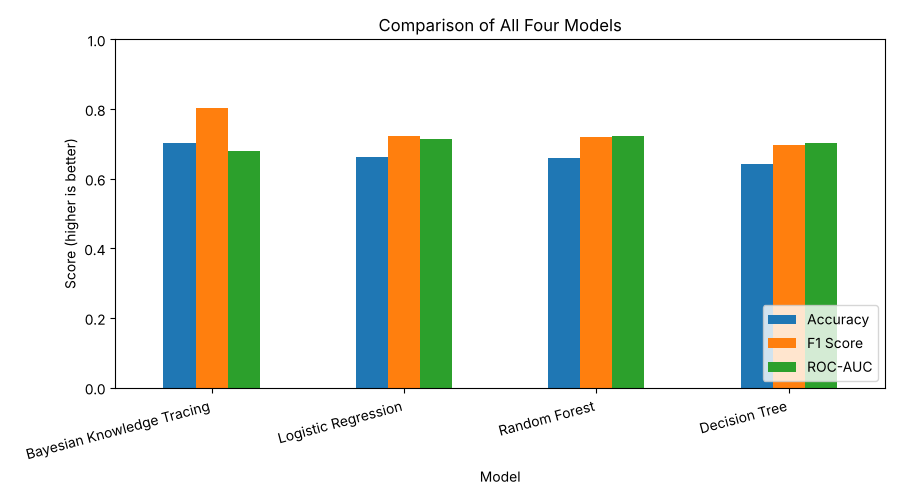

In [ ]:
metrics_to_plot = ["Accuracy", "F1 Score", "ROC-AUC"]
plot_df = all_model_results.set_index("Model")[metrics_to_plot]

plot_df.plot(kind="bar", figsize=(9, 5))
plt.title("Comparison of All Four Models")
plt.ylabel("Score (higher is better)")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### What the comparison tells us
- **BKT** has the best accuracy (70.2%), F1, Brier score and log loss, meaning its probabilities are the most trustworthy.
- **Random Forest** has the best ROC-AUC (0.722), so it is best at ranking answers from "likely wrong" to "likely correct".
- **Logistic Regression** is close behind and is the simplest of the machine-learning models.
- **Decision Tree** is the weakest on almost every score.
- **Fairness note:** the three classifiers use *balanced* class weights, which lowers their accuracy but helps them detect wrong answers. BKT uses a 0.5 cut-off and mostly predicts "correct". Because of this, **ROC-AUC (which ignores the cut-off)** is the fairest single score for comparing them, and there Random Forest > Logistic Regression > Decision Tree > BKT.
- The overall gap between models is small, so no model is a clear winner on every measure.

## 22. Adaptive Learning Recommendations Using BKT
**In simple words:** This is the practical use. For every student-skill pair, BKT gives a final mastery estimate, and we turn it into advice:

| Situation | Recommendation |
|---|---|
| Fewer than 3 answers | **Collect More Practice Data** |
| Mastery below 0.50 | **Recommend More Practice** |
| Mastery 0.50 to 0.90 | **Continue Practice** |
| Mastery 0.90 or above | **Consider Next Skill** |

The thresholds (0.50, 0.90, 3 answers) are our own simple rules, not fixed standards. This report uses the full cleaned data.

In [24]:
def classify_mastery(probability):
    if probability < 0.50:
        return "Needs More Practice"
    elif probability < 0.90:
        return "Developing"
    return "Potentially Mastered"


def make_recommendation(final_mastery, num_responses):
    if num_responses < 3:
        return "Collect More Practice Data"
    elif final_mastery < 0.50:
        return "Recommend More Practice"
    elif final_mastery < 0.90:
        return "Continue Practice"
    return "Consider Next Skill"


def create_mastery_report(sequence_frame, params):
    p_l0, p_transition, p_guess, p_slip = params
    report = []

    for (user_id, skill_id), group in sequence_frame.groupby(
        ["user_id", "skill_id"], sort=False
    ):
        group = group.sort_values("order_id")
        mastery = p_l0

        for response in group["correct"].astype(int):
            mastery = update_mastery(
                mastery, response, p_guess, p_slip
            )
            mastery = learning_transition(
                mastery, p_transition
            )

        count = len(group)

        report.append({
            "user_id": user_id,
            "skill_id": skill_id,
            "skill_name": group["skill_name"].iloc[-1],
            "num_responses": count,
            "final_mastery": mastery,
            "mastery_category": classify_mastery(mastery),
            "recommendation": make_recommendation(mastery, count)
        })

    return pd.DataFrame(report)


bkt_mastery_report = create_mastery_report(
    data, bkt_parameters
)

display(bkt_mastery_report.head(10))

,user_id,skill_id,skill_name,num_responses,final_mastery,mastery_category,recommendation
0,14,13,Median,4,0.100694,Needs More Practice,Recommend More Practice
1,14,15,Range,3,0.987946,Potentially Mastered,Consider Next Skill
2,14,2_37_48,Circle Graph,2,0.963831,Potentially Mastered,Collect More Practice Data
3,14,2_37_48_77,Circle Graph,2,0.251162,Needs More Practice,Collect More Practice Data
4,14,2_37_70,Circle Graph,6,0.101024,Needs More Practice,Recommend More Practice
5,14,2_48_79,Circle Graph,2,0.251162,Needs More Practice,Collect More Practice Data
6,21825,10_12,Table,4,0.964432,Potentially Mastered,Consider Next Skill
7,21825,10_13,Table,3,0.479124,Needs More Practice,Recommend More Practice
8,21825,279,Multiplication and Division Integers,10,0.999995,Potentially Mastered,Consider Next Skill
9,51950,311,Equation Solving Two or Fewer Steps,4,0.964432,Potentially Mastered,Consider Next Skill


## 23. Visualising Mastery and Recommendations
**In simple words:** The first chart shows how mastery estimates are spread. The second shows how many student-skill pairs get each recommendation.

**What we see:** Roughly 18,000 sequences are ready for the **next skill** and a similar number (about 17,500) have **too little data**, because many sequences are short. About 3,500 need **more practice** and about 3,800 should **continue practising**.

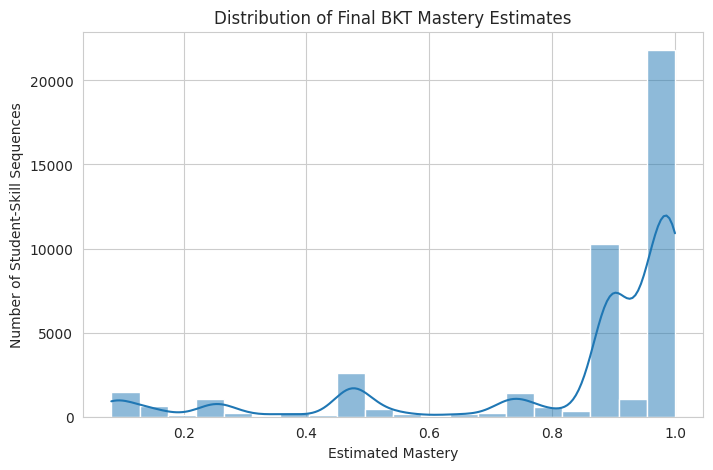

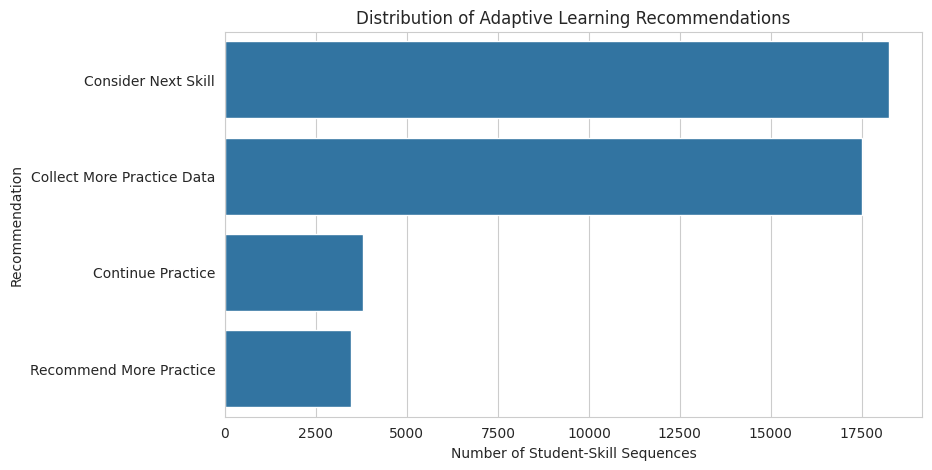

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(
    bkt_mastery_report["final_mastery"],
    bins=20,
    kde=True
)
plt.title("Distribution of Final BKT Mastery Estimates")
plt.xlabel("Estimated Mastery")
plt.ylabel("Number of Student-Skill Sequences")
plt.show()

plt.figure(figsize=(9, 5))
sns.countplot(
    data=bkt_mastery_report,
    y="recommendation",
    order=bkt_mastery_report["recommendation"].value_counts().index
)
plt.title("Distribution of Adaptive Learning Recommendations")
plt.xlabel("Number of Student-Skill Sequences")
plt.ylabel("Recommendation")
plt.show()

## 24. Saving Results
**In simple words:** We save the comparison table, the mastery report and the BKT predictions as CSV files so they can be reused (for example with the second dataset).

In [27]:
all_model_results.to_csv(
    "ASSISTments_Model_Comparison.csv",
    index=False
)

bkt_mastery_report.to_csv(
    "ASSISTments_BKT_Mastery_Report.csv",
    index=False
)

bkt_test_results.to_csv(
    "ASSISTments_BKT_Test_Predictions.csv",
    index=False
)

print("Result files saved successfully.")

Result files saved successfully.


## 25. Conclusion
- We cleaned the ASSISTments data (283,105 answers, 4,163 students) and tested all models on **students the models had never seen**.
- **BKT** was the most accurate model (70.2%) and gave the best probability estimates. It also **explains learning**, because it tracks mastery of each skill over time.
- **Random Forest** was best at ranking correct vs incorrect answers (ROC-AUC 0.722), but it is harder to explain.
- **Logistic Regression** performed almost as well as Random Forest and is simple to interpret. **Decision Tree** performed worst.
- BKT's mastery estimates can drive **adaptive recommendations** (practise more, continue, or move to the next skill).

## 26. Limitations
- About 18% of rows had no skill ID and were removed.
- Many student-skill sequences are short (median 4 answers), so mastery estimates are uncertain for them.
- BKT used a sample of 10,000 sequences to fit its parameters, and one set of parameters is used for all skills.
- The classification models were not tuned heavily, and recommendation thresholds are simple rules.
- Differences between models are modest, so results may change with other data.

## 27. Possible Future Work
- Fit BKT parameters **per skill**.
- Tune the Decision Tree and Random Forest settings.
- Repeat the study on the second dataset and compare the findings.

## Appendix: Metric Guide (for quick explanation)
| Metric | Simple meaning | Better is |
|---|---|---|
| **Accuracy** | % of all answers predicted correctly | Higher |
| **Precision** | When the model says "correct", how often it is right | Higher |
| **Recall** | Of all truly correct answers, how many the model found | Higher |
| **F1 Score** | One number that balances precision and recall | Higher |
| **ROC-AUC** | How well the model ranks correct answers above wrong ones (0.5 = guessing, 1 = perfect) | Higher |
| **Brier Score** | Average squared error of the predicted probabilities | Lower |
| **Log Loss** | Penalty for confident but wrong probabilities | Lower |

## Appendix: Questions you may be asked (with simple answers)
**1. Why split by student and not by row?**
If the same student appeared in both groups, the model could "remember" them and look better than it really is. Splitting by student tests on completely new students.

**2. What is BKT in one line?**
A model that keeps a running probability that a student has learned a skill, and updates it after every answer.

**3. What are guess and slip?**
Guess = getting it right without knowing the skill. Slip = getting it wrong even though the skill is known.

**4. Which model is the best?**
BKT has the best accuracy and probability scores and explains learning. Random Forest has the best ROC-AUC. The differences are small, so it depends on the goal.

**5. Why do the classifiers have lower accuracy than BKT?**
They use balanced class weights so they also catch wrong answers. This costs some accuracy.

**6. Why is accuracy only about 65 to 70%?**
Student answers are noisy (guessing, slips, carelessness), and we only use simple features from earlier answers.

**7. Why were many rows removed?**
About 18% of rows had no skill ID, and BKT needs the skill.

**8. How are the recommendations made?**
From BKT's final mastery estimate: below 0.50 means more practice, 0.50 to 0.90 means continue, 0.90 or above means move on, and fewer than 3 answers means collect more data. These thresholds are our own simple rules.

**9. What would you improve?**
Fit BKT parameters for each skill separately and tune the Decision Tree and Random Forest.